# Week 2 - Task 1: Data Cleaning
**Dataset:** Global Superstore

Goal: clean the raw dataset and create a cleaned CSV file.

## Step 1 - Import Libraries
Pandas handles data, NumPy handles numbers, and Seaborn/Matplotlib create charts.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

print('Libraries imported successfully!')

Libraries imported successfully!


## Step 2 - Upload Dataset
Run this cell and select your Global Superstore Excel file.

In [2]:
from google.colab import files
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
print('Uploaded file:', file_name)

Saving global_superstore_cleaned.csv to global_superstore_cleaned.csv
Uploaded file: global_superstore_cleaned.csv


## Step 3 - Load Orders Sheet

In [6]:
import os

print("Uploaded file:", file_name)

if file_name.lower().endswith(".csv"):
    df = pd.read_csv(file_name)

elif file_name.lower().endswith(".xlsx"):
    df = pd.read_excel(file_name, sheet_name="Orders")

elif file_name.lower().endswith(".xls"):
    df = pd.read_excel(file_name, sheet_name="Orders")

else:
    print("Wrong file format. Please upload CSV or Excel file.")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Uploaded file: global_superstore_cleaned.csv
Dataset loaded successfully!
Rows: 51290
Columns: 24


## Step 4 - View First 5 Rows

In [7]:
df.head()

,row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,city,state,...,product_id,category,sub_category,product_name,sales,quantity,discount,profit,shipping_cost,order_priority
0,32298,CA-2012-124891,2012-07-31,2012-07-31,Same Day,RH-19495,Rick Hansen,Consumer,New York City,New York,...,TEC-AC-10003033,Technology,Accessories,Plantronics CS510 - Over-the-Head monaural Wir...,581.495063,7.0,0.0,92.025,57.21,Critical
1,26341,IN-2013-77878,2013-02-05,2013-02-07,Second Class,JR-16210,Justin Ritter,Corporate,Wollongong,New South Wales,...,FUR-CH-10003950,Furniture,Chairs,"Novimex Executive Leather Armchair, Black",581.495063,9.0,0.1,-55.215,57.21,Critical
2,25330,IN-2013-71249,2013-10-17,2013-10-18,First Class,CR-12730,Craig Reiter,Consumer,Brisbane,Queensland,...,TEC-PH-10004664,Technology,Phones,"Nokia Smart Phone, with Caller ID",581.495063,9.0,0.1,92.025,57.21,Medium
3,13524,ES-2013-1579342,2013-01-28,2013-01-30,First Class,KM-16375,Katherine Murray,Home Office,Berlin,Berlin,...,TEC-PH-10004583,Technology,Phones,"Motorola Smart Phone, Cordless",581.495063,5.0,0.1,-55.215,57.21,Medium
4,47221,SG-2013-4320,2013-11-05,2013-11-06,Same Day,RH-9495,Rick Hansen,Consumer,Dakar,Dakar,...,TEC-SHA-10000501,Technology,Copiers,"Sharp Wireless Fax, High-Speed",581.495063,8.0,0.0,92.025,57.21,Critical


## Step 5 - Check Dataset Information

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   row_id          51290 non-null  int64  
 1   order_id        51290 non-null  object 
 2   order_date      51290 non-null  object 
 3   ship_date       51290 non-null  object 
 4   ship_mode       51290 non-null  object 
 5   customer_id     51290 non-null  object 
 6   customer_name   51290 non-null  object 
 7   segment         51290 non-null  object 
 8   city            51290 non-null  object 
 9   state           51290 non-null  object 
 10  country         51290 non-null  object 
 11  postal_code     51290 non-null  object 
 12  market          51290 non-null  object 
 13  region          51290 non-null  object 
 14  product_id      51290 non-null  object 
 15  category        51290 non-null  object 
 16  sub_category    51290 non-null  object 
 17  product_name    51290 non-null 

## Step 6 - Check Missing Values

In [9]:
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

Series([], dtype: int64)


## Step 7 - Missing Values Heatmap

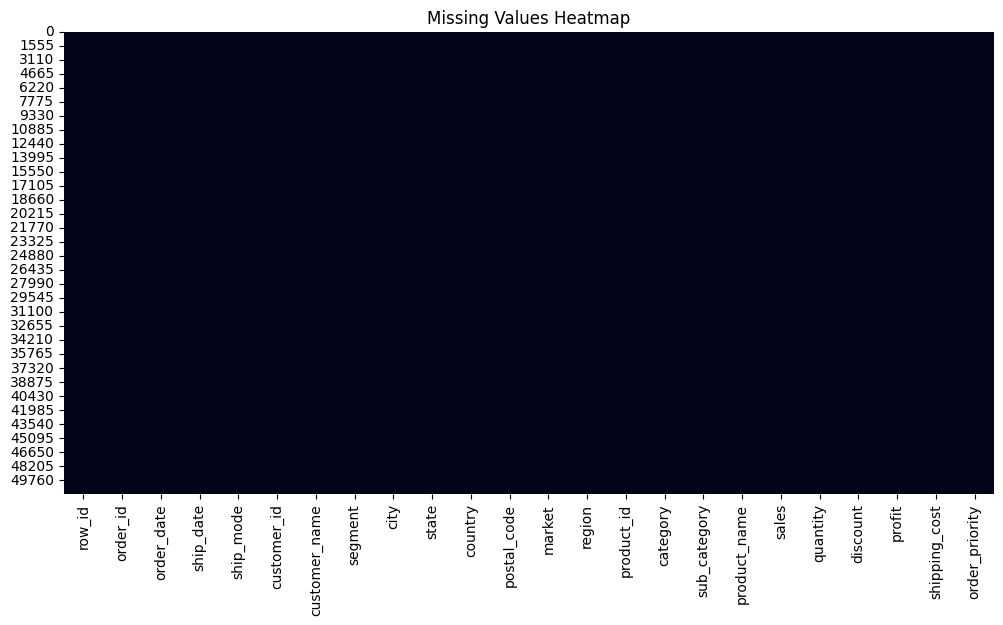

In [10]:
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(), cbar=False)
plt.title('Missing Values Heatmap')
plt.show()

## Step 8 - Remove Duplicate Rows

In [11]:
print('Duplicate rows:', df.duplicated().sum())
df = df.drop_duplicates()
print('Rows after removing duplicates:', len(df))

Duplicate rows: 0
Rows after removing duplicates: 51290


## Step 9 - Standardize Column Names

In [13]:
df.columns = (df.columns.str.strip().str.lower().str.replace(' ','_').str.replace('-','_'))
print(df.columns.tolist())

['row_id', 'order_id', 'order_date', 'ship_date', 'ship_mode', 'customer_id', 'customer_name', 'segment', 'city', 'state', 'country', 'postal_code', 'market', 'region', 'product_id', 'category', 'sub_category', 'product_name', 'sales', 'quantity', 'discount', 'profit', 'shipping_cost', 'order_priority']


## Step 10 - Correct Date Types

In [12]:
for col in ['order_date','ship_date']:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')
print('Date columns checked.')

Date columns checked.


## Step 11 - Find Numeric Columns

In [14]:
numeric_columns = df.select_dtypes(include=np.number).columns
print(list(numeric_columns))

['row_id', 'sales', 'quantity', 'discount', 'profit', 'shipping_cost']


## Step 12 - Detect Outliers using IQR
IQR (Interquartile Range) helps identify unusually low or high values.

In [15]:
outlier_summary = {}
for col in numeric_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier_summary[col] = ((df[col] < lower) | (df[col] > upper)).sum()
pd.Series(outlier_summary, name='outlier_count')

,outlier_count
row_id,0
sales,0
quantity,0
discount,0
profit,0
shipping_cost,5909


## Step 13 - Box Plot

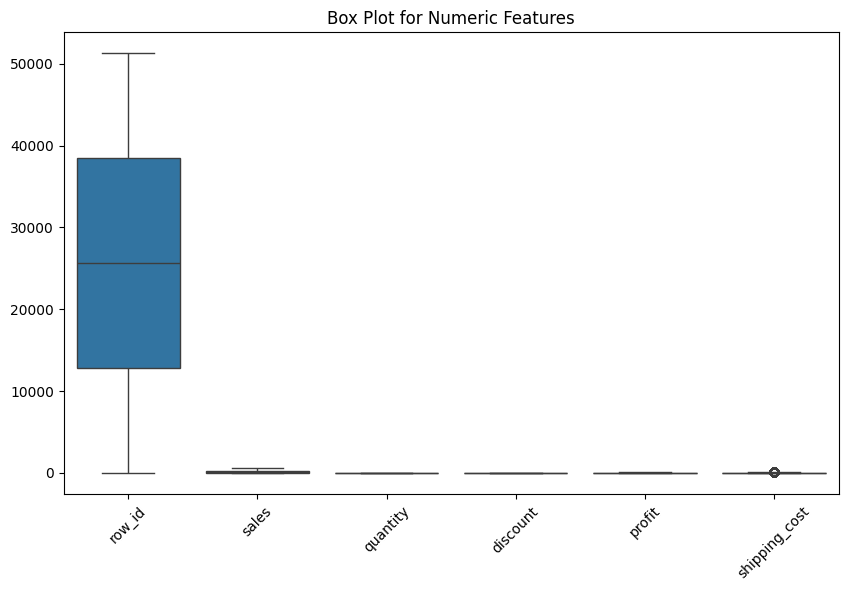

In [16]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[numeric_columns])
plt.xticks(rotation=45)
plt.title('Box Plot for Numeric Features')
plt.show()

## Step 14 - Final Validation

In [17]:
print('Final rows:', df.shape[0])
print('Final columns:', df.shape[1])
print('Total missing values:', df.isnull().sum().sum())
print('Total duplicate rows:', df.duplicated().sum())

Final rows: 51290
Final columns: 24
Total missing values: 0
Total duplicate rows: 0


## Step 15 - Export Cleaned CSV

In [18]:
output_file = 'global_superstore_cleaned.csv'
df.to_csv(output_file, index=False)
print('Cleaned dataset created:', output_file)

Cleaned dataset created: global_superstore_cleaned.csv


## Step 16 - Download Cleaned CSV

In [19]:
files.download('global_superstore_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
The Global Superstore dataset was inspected and cleaned by checking missing values, duplicates, column names, date types, and numerical outliers. The cleaned dataset was exported for Task 2 and Task 3.